# Particle in a box:

In [5]:
# 7 Oct
import numpy as np
import matplotlib.pyplot as plt

# Preamble

In [6]:
n = 1001
xmin = -0.2 * 10**(-9)  # m
xmax = 0.2 * 10**(-9)  # m
delx = (xmax - xmin)/(n-1)
x = np.linspace(xmin, xmax, n)
h_bar = 1.054 * 10**(-34)  # J/s
m = 9.1 * 10**(-31)  #kg
e = 1.6 * 10**(-19)  #C
c = (h_bar**2)/(2*m*e*delx**2)
# print(c)
a = 0.2 *10**(-9)    # Well width in m

In [7]:
v = np.zeros(n)

for i in range(n):
    if (abs(x[i])<= 0.1*10**(-9)):
        v[i] = 0
    else:
        v[i] = 100000  # eV
        
V = v[1:n-1]
pe = np.diag( V)

ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) )

H = ke+pe

eig_val, eig_vec = np.linalg.eigh(H)
# No counter needed, no bound state. But take:
count = 4

xnew = x[1:n-1]

In [8]:
print("Energy eigenvalues of first", count, "states : ", eig_val[0:count], "eV")

a = 0.2 *10**(-9)    # Well width in m
E_th = np.zeros(count)
for i in range(count):
    N = i + 1
    E_n = ( (N* np.pi * h_bar)**2 )/(2*m*a*a*e)
    print("Theoretical energy value for state", n, "is: ", E_n, "eV")
    E_th[i] = E_n

print("[theoretical calulation; E_n = (n^2*pi^2*h_bar^2)/(2m*a^2*e) ]")


Energy eigenvalues of first 4 states :  [  9.25513994  37.02018475  83.29400932 148.07473848] eV
Theoretical energy value for state 1001 is:  9.413033518922202 eV
Theoretical energy value for state 1001 is:  37.65213407568881 eV
Theoretical energy value for state 1001 is:  84.7173016702998 eV
Theoretical energy value for state 1001 is:  150.60853630275523 eV
[theoretical calulation; E_n = (n^2*pi^2*h_bar^2)/(2m*a^2*e) ]


/tmp/ipykernel_90769/3334117281.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


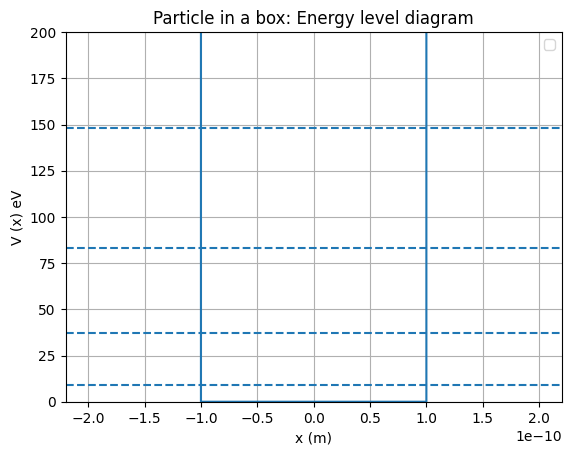

In [ ]:
plt.plot(x, v)
plt.title("Particle in a box: Energy level diagram")
for i in range(count):
    plt.axhline (y=eig_val[i], ls= '--')
plt.xlabel("x (m)")
plt.ylabel("V (x) eV")
plt.ylim(0,200)
plt.grid()
plt.show()

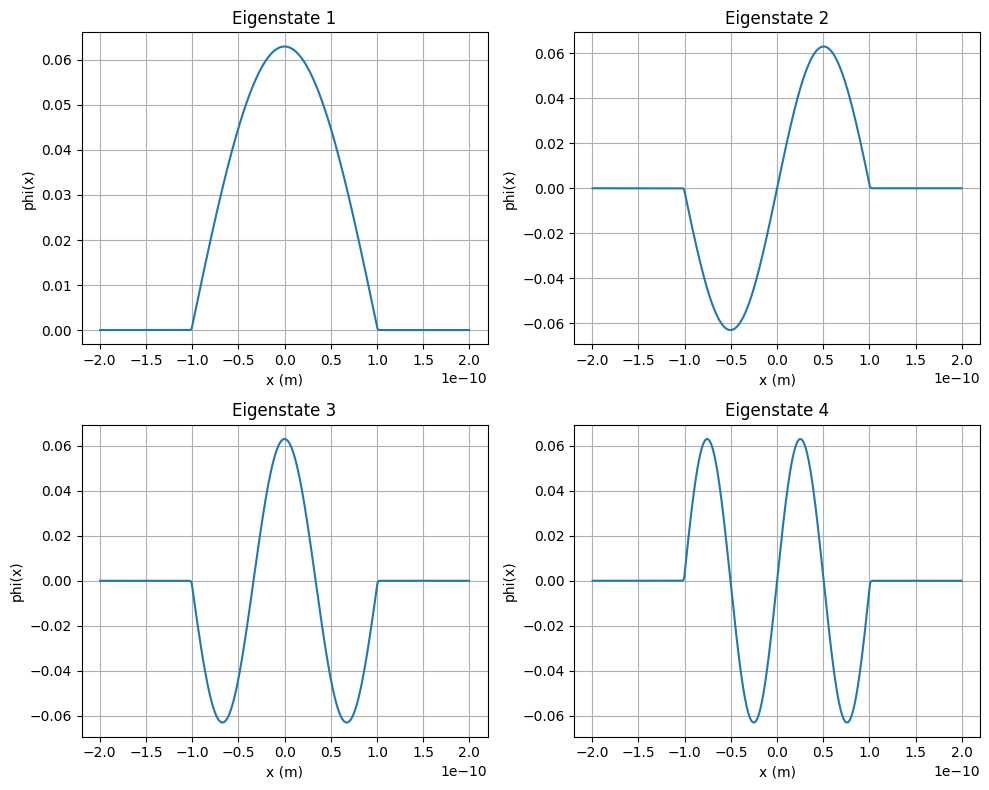

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10,8))
for i in range(2):
    for j in range(2):
        eig_state = 2*i + j
        ax[i,j].plot(xnew, eig_vec[:,eig_state])
        ax[i,j].set_title(f"Eigenstate {eig_state + 1}")
        ax[i,j].set_xlabel("x (m)")
        ax[i,j].set_ylabel("psi(x)")
        ax[i,j].grid()
plt.tight_layout()
plt.show()

### Normalise (each eigen function ,i.e. 4)
integral of psi**2 dx
[But eigh gives already normalised eig_vec]

for i in range(count):

    yp = eig_vec[:,i]*eig_vec[:,i]
    norm_sq = np.trapezoid(yp, xnew)

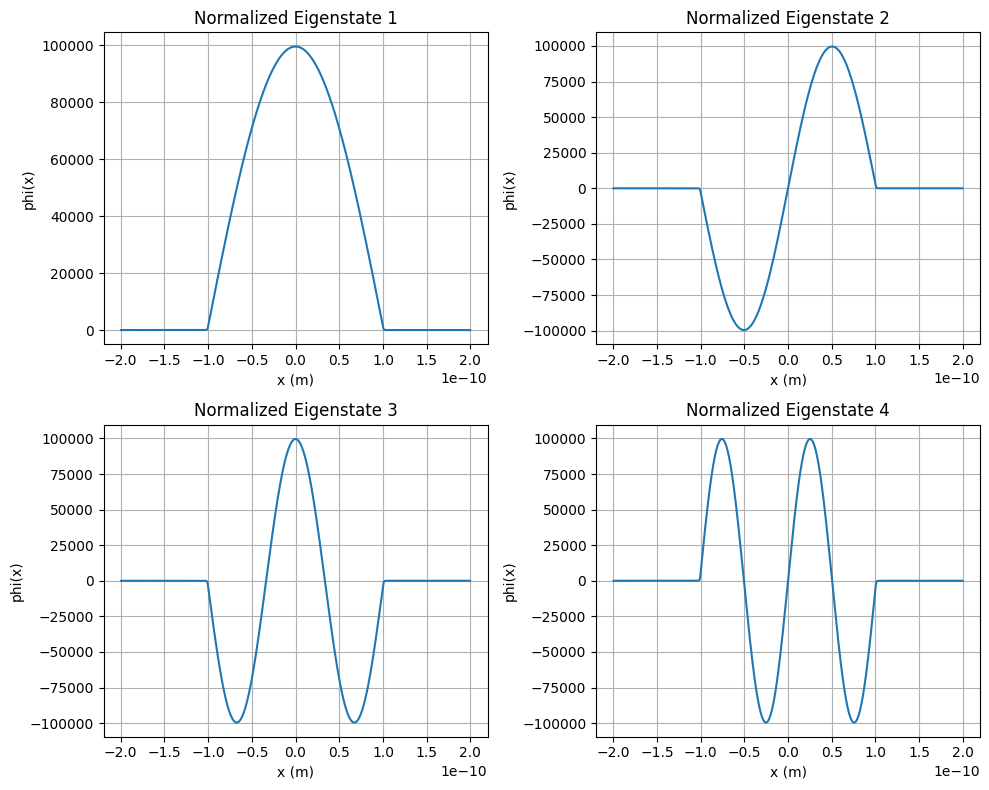

In [19]:
# print(xnew.shape, eig_vec[:,0].shape)
psi = np.zeros((n-2, count))   # Normalized wavefunction of eig_vec will be stored here
for i in range(count):
    yp = eig_vec[:,i]*eig_vec[:,i]
    norm_sq = np.trapezoid(yp, xnew)
    norm = np.sqrt(norm_sq)
    # print("Normalization factor for state", i+1, "is: ", norm)
    psi[:,i] = eig_vec[:,i]/norm

fig, ax = plt.subplots(2, 2, figsize = (10,8))
for i in range(2):
    for j in range(2):
        eig_state = 2*i + j
        ax[i,j].plot(xnew, psi[:,eig_state])
        ax[i,j].set_title(f"Normalized Eigenstate {eig_state + 1}")
        ax[i,j].set_xlabel("x (m)")
        ax[i,j].set_ylabel("phi(x)")
        ax[i,j].grid()
plt.tight_layout()
plt.show()
    

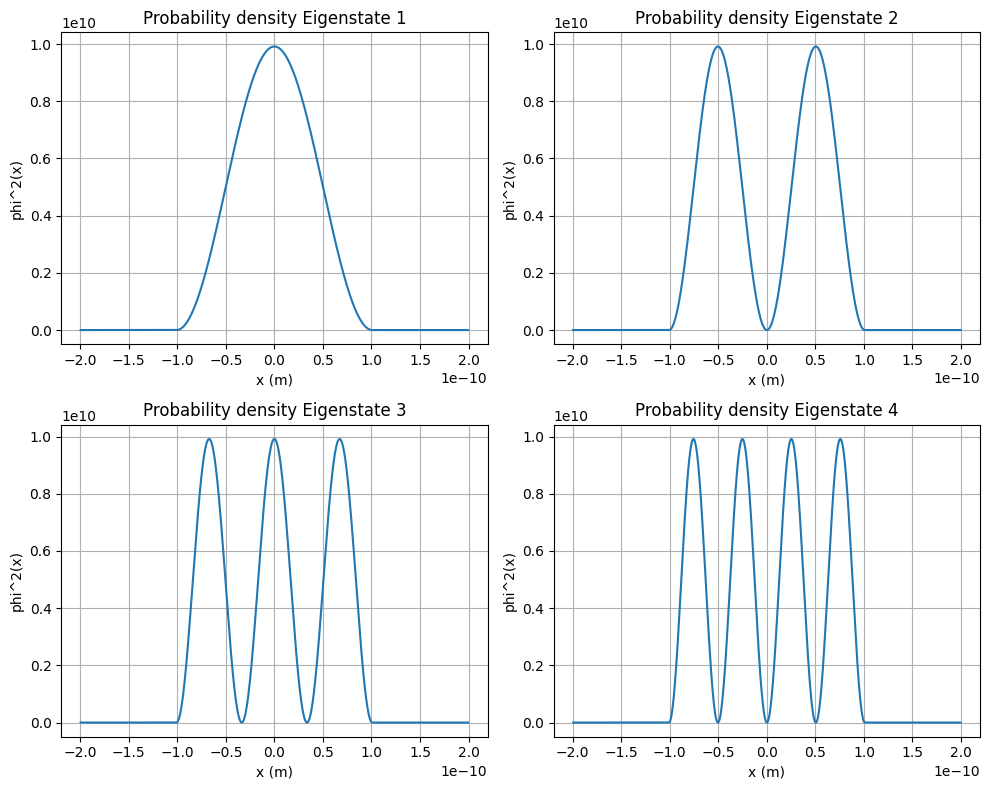

In [20]:
fig, ax = plt.subplots(2, 2, figsize = (10,8))
for i in range(2):
    for j in range(2):
        eig_state = 2*i + j
        ax[i,j].plot(xnew, psi[:,eig_state]*psi[:,eig_state])
        ax[i,j].set_title(f"Probability density Eigenstate {eig_state + 1}")
        ax[i,j].set_xlabel("x (m)")
        ax[i,j].set_ylabel("phi^2(x)")
        ax[i,j].grid()
plt.tight_layout()
plt.show()

### Expectation val.

In [ ]:
exp_x = np.zeros(count)
exp_x2 = np.zeros(count)
exp_v = np.zeros(count)

exp_p = np.zeros(count)
exp_p2 = np.zeros(count)
exp_ke = np.zeros(count)

diff_psi = (psi[1:,:] - psi[:-1,:])/delx  # shape of diff_psi is (n-3, count)
xmid = (xnew[1:] + xnew[:-1])/2  # x_i = (x[i] + x[i+1])/2;  (everything except the first - everything except the last)/2
psi_mid = (psi[1:,:] + psi[:-1,:])/2

diff2_psi = (diff_psi[1:,:] - diff_psi[:-1,:])/delx  # shape of diff2_psi is (n-4, count)
psi_mid2 = psi[1:-1,:]  # shape of psi_mid2 is (n-4, count); exclude 1st & last point 
xmid2 = xnew[1:-1]

sigma_x = np.zeros(count)
sigma_p = np.zeros(count)
sigma_xp = np.zeros(count)
# sigma_x * sigma_p >= h_bar/2 --> (sigma_x * sigma_p)*2/h_bar >= 1
 
print(xmid.shape, xmid2.shape, diff2_psi.shape, diff_psi.shape)

(998,) (997,) (997, 4) (998, 4)


In [28]:
print("Calculating expectation values for state:")
for i in range(count):
    print("\nbound state",i+1)
    yp = xnew* psi[:,i]**2
    # <x> = psi(x)^2 * x
    exp_x[i]= np.trapezoid(yp, xnew)
    
    # <x^2> = psi(x)^2 * x^2
    yp2 = (xnew* psi[:,i])**2
    exp_x2[i] = np.trapezoid(yp2, xnew)
    
    # <V> = psi(x)^2 * V(x)
    yp3 = V * psi[:,i]**2
    #print("yp3 shape: ", yp3.shape, "xnew shape: ", xnew.shape)
    exp_v[i] = np.trapezoid(yp3, xnew)
    
    print("<x> = ", exp_x[i])
    print("<x^2> = ", exp_x2[i])
    print("<V> = ", exp_v[i])
    
    # <p> = -i*h_bar*(psi*(x) d(psi)/dx)
    yp4 = (psi_mid[:,i] * diff_psi[:,i])
    #print("yp4 shape: ", yp4.shape, "xmid shape: ", xmid.shape)
    exp_p[i] = (-1) * h_bar * np.trapezoid(yp4, xmid) 
    print("<p> = ", exp_p[i] * 1j)
    
    # <p^2> = -h_bar^2 *(psi*(x) d2(psi)/dx2)
    yp5 = psi_mid2[:,i]*diff2_psi[:,i]
    exp_p2[i]= np.trapezoid(yp5, xmid2) * (-1 * h_bar**2)
    print("<p^2> = ", exp_p2[i])
    
    # <k> = <p^2>/2m
    exp_ke[i] = exp_p2[i]/(2*m*e)
    print("<KE> = ", exp_ke[i])
    
    print("Total energy = <KE> + <V> = ", exp_ke[i] + exp_v[i], f"eV = E_{i+1} = ", eig_val[i], "eV")
    
    # Uncertainty in x = sqrt(<x^2> - <x>^2)
    var_x = exp_x2[i] - (exp_x[i]**2)
    sigma_x[i] = np.sqrt(var_x)
    var_p = exp_p2[i] - (exp_p[i]**2)
    sigma_p[i] = np.sqrt(var_p)
    
    sigma_xp[i] = sigma_x[i] * sigma_p[i]
    
print( "Ratio of (sigma_x * sigma_p)/(h_bar/2) :", (2/h_bar) * sigma_xp," with increasing i (should be >= 1)")

Calculating expectation values for state:

bound state 1
<x> =  5.492996255234949e-25
<x^2> =  1.329202624259179e-21
<V> =  0.05392886731291269
<p> =  (-0+0j)
<p^2> =  2.6793926656757687e-48
<KE> =  9.20121107718327
Total energy = <KE> + <V> =  9.255139944496182 eV = E_1 =  9.255139944649299 eV

bound state 2
<x> =  7.754818242684634e-25
<x^2> =  2.8749477414805403e-21
<V> =  0.21573966305878492
<p> =  (-0-1.0876283049583435e-40j)
<p^2> =  1.0717454408693864e-47
<KE> =  36.80444508480035
Total energy = <KE> + <V> =  37.02018474785913 eV = E_2 =  37.02018474801209 eV

bound state 3
<x> =  2.287671381591967e-24
<x^2> =  3.1612032795473205e-21
<V> =  0.4855050201815112
<p> =  (-0+0j)
<p^2> =  2.4113836450891726e-47
<KE> =  82.80850429564465
Total energy = <KE> + <V> =  83.29400931582616 eV = E_3 =  83.2940093159788 eV

bound state 4
<x> =  -6.4106497472859645e-24
<x^2> =  3.261400336270818e-21
<V> =  0.8633461655448187
<p> =  3.84792685508728e-41j
<p^2> =  4.2867957441469406e-47
<KE> =  1

In [29]:
print("Sensitivity of bound state energies to the choice of n?")
for i in (501,1001,2001):
    n = i
    delx = (xmax - xmin)/(n-1)
    x = np.linspace(xmin, xmax, n)
    c = (h_bar**2)/(2*m*e*delx**2)
    print("\nFor n =", n, ",c =", c)
    
    ke = (-c) * (np.eye((n-2), k=1) + (-2)*np.eye(n-2) + np.eye((n-2), k=-1))
    
    v = np.zeros(n)
    for j in range(n):
        if (abs(x[j])<= 0.1*10**(-9)):
            v[j] = 0
        else:
            v[j] = 100000  # eV
    pe = np.diag(v[1:n-1])
    
    H = ke + pe
    eig_val, eig_vec = np.linalg.eigh(H)
    
    print("Energy eigenvalues of the first", 4, "states are: ", eig_val[0:4])

N = np.array([1,2,3,4])
E_n = ( (N* np.pi * h_bar)**2 )/(2*m*a*a*e)
print("\nTheoretical energy value is: ", E_n, "eV") 
 
print("The sensitivity of the bound state energies to the choice of n is very low. The eigenvalues are almost the same for n = 501, 1001, and 2001.")
print("The theoretical energy values are also very close to the numerical values obtained from the eigenvalue problem.")

Sensitivity of bound state energies to the choice of n?

For n = 501 ,c = 59608.731112637324
Energy eigenvalues of the first 4 states are:  [  9.20266533  36.80923777  82.81544688 147.214176  ]

For n = 1001 ,c = 238434.9244505493
Energy eigenvalues of the first 4 states are:  [  9.25513994  37.02018475  83.29400932 148.07473848]

For n = 2001 ,c = 953739.6978021972
Energy eigenvalues of the first 4 states are:  [  9.27787719  37.11139874  83.50023461 148.44383465]

Theoretical energy value is:  [  9.41303352  37.65213408  84.71730167 150.6085363 ] eV
The sensitivity of the bound state energies to the choice of n is very low. The eigenvalues are almost the same for n = 501, 1001, and 2001.
The theoretical energy values are also very close to the numerical values obtained from the eigenvalue problem.


In [30]:
n = 1001
delx = (xmax - xmin)/(n-1)
c = (h_bar**2)/(2*m*e*delx**2)
v0 = [10**(5), 10**(6), 10**(7)]
print("Varying the height of the potential box, V0")
for i in range(len(v0)):
    
    v = np.zeros(n)
    for j in range(n):
        if (abs(x[j])<= 0.1*10**(-9)):
            v[j] = 0
        else:
            v[j] = v0[i]  # eV
    pe = np.diag(v[1:n-1])
    
    ke = (-c) * (np.eye((n-2), k=1) + (-2)*np.eye(n-2) + np.eye((n-2), k=-1))
    
    H = ke + pe
    eig_val, eig_vec = np.linalg.eigh(H)
    
    print("\nFor V0 =", v0[i], "eV, Energy eigenvalues of the first", 4, "states are: ", eig_val[0:4])

Varying the height of the potential box, V0



For V0 = 100000 eV, Energy eigenvalues of the first 4 states are:  [  9.33357064  37.33390913  83.99989522 149.32966182]

For V0 = 1000000 eV, Energy eigenvalues of the first 4 states are:  [  9.36802427  37.47172927  84.31001161 149.88103234]

For V0 = 10000000 eV, Energy eigenvalues of the first 4 states are:  [  9.37459132  37.49799675  84.36911076 149.98609083]
